**Human Movement Intelligence | Presented by: Reza Saadatyar (2026)**

**22 | Unified Matched Benchmark: Seven HARTH Activity Classifiers**

![Stage 22 scientific workflow](https://raw.githubusercontent.com/RezaSaadatyar/human-movement-intelligence/main/wearable_activity_recognition/images/22_workflow.svg)

**Objective:** Evaluate Random Forest, two CNN baselines, TCN, Multi-Scale CNN, 1D-ResNet and Time-Series Transformer on identical participant-held-out Development windows.

**Dataset:** The pinned HARTH v2.0 Development cohort: 29 participants, 14,201 label-pure 500-cap windows and eight documented activity codes. Reserved Test IDs S023 and S032 are not loaded.

**Notebook Scope:** Fit seven classifiers across three common GroupKFold splits, verify the 21 model-fold jobs and compare out-of-fold metrics, class errors, participant-level performance and computational cost. This is a matched Development benchmark, not independent final Test or external validation.

**Comparison basis:** Random Forest uses 30 deterministic features and 120 trees; neural models use the corresponding six-channel sequences and 400 Adam updates. Scaling and class weighting use fold Train only. Equal updates do not equalise computational cost, convergence or data exposure.

**00. Colab Repository Setup**

In [1]:
# ======================== 00. Colab Repository Setup =========================

# -------------------------- 1. Repository Checkout ---------------------------
from pathlib import Path

repo_url = "https://github.com/RezaSaadatyar/human-movement-intelligence.git"
repo_path = Path("/content") / repo_url.split("/")[-1].removesuffix(".git")
%cd /content

if not repo_path.exists():
    !git clone -q {repo_url}

# ---------------------------- 2. Open Repository -----------------------------
%cd {repo_path}


/content
/content/human-movement-intelligence


**01. Imports and Fixed Research Protocol**

In [2]:
# ================== 01. Imports and Fixed Research Protocol ==================

# ------------------------ 1. Study Environment Setup -------------------------
from python_modules.core.colab_setup import setup_colab
root = setup_colab("wearable_activity_recognition")

# ----------------- 2. Scientific Computing and Data Analysis -----------------
import numpy as np
import pandas as pd

# ------------------- 3. Visualisation and Notebook Display -------------------
import matplotlib.pyplot as plt
from IPython.display import display
from core.plot_style import plot_style, save_figure

plot_style(font_family="DejaVu Sans", title_size=12.5, title_weight="normal",
    label_size=11.5, label_weight="normal", tick_size=11, legend_size=10,
    figure_dpi=100, figure_size=(9, 4))

# ------------------------ 4. Deep Learning Framework -------------------------
import torch

# --------------------- 5. HARTH and Benchmark Utilities ----------------------
from core.output_download import download_outputs_from_colab
from harth_data import (
    HARTH_SUBJECTS, HARTH_REVISION, SENSOR_COLUMNS, ACTIVITY_NAMES,
    prepare_harth_window_cohort
)
from core.temporal_benchmark import (
    MODEL_NAMES, PROTOCOL_VERSION, make_benchmark_plan,
    run_benchmark_job, summarise_benchmark_results
)
from core.feature_engineering import extract_signal_features

# ---------------- 6. Development Cohort and Training Protocol ----------------
RESERVED_TEST={"S023","S032"}
DEVELOPMENT_SUBJECTS=sorted(set(HARTH_SUBJECTS)-RESERVED_TEST)
CLASSES=tuple(range(1,9))
FOLDS=3
MAX_WINDOWS_PER_SUBJECT=500
MAX_STEPS=400
BATCH_SIZE=128
SEED=42

# ------------------ 7. Required GPU and Precision Controls -------------------
from core.computer_device import computer_device
device = computer_device()
DEVICE = device.type
REQUIRE_CUDA = True
if REQUIRE_CUDA and DEVICE != "cuda":
    raise RuntimeError("A CUDA GPU is required for the approved benchmark.")
if DEVICE == "cuda":
    torch.set_float32_matmul_precision("highest")
    torch.backends.cuda.matmul.allow_tf32 = False
    torch.backends.cudnn.allow_tf32 = False

# ------------------ 8. Benchmark Cache and Cohort Integrity ------------------
CACHE_DIR=root/"data/processed/harth_stage23_matched_benchmark"
assert len(DEVELOPMENT_SUBJECTS)==29 and not(set(DEVELOPMENT_SUBJECTS)&RESERVED_TEST)
assert len(MODEL_NAMES)==7

# ------------------ 9. Research Evidence Output Directory -------------------
output_dir = root / "wearable_activity_recognition" / "output"
output_dir.mkdir(parents=True, exist_ok=True)

# ----------------------- 9. Experiment Setup Summary ------------------------
print(""+"="*70)
print("STAGE 22 | SEVEN-MODEL MATCHED DEVELOPMENT BENCHMARK")
print("="*70)
print("Pinned official HARTH revision:", HARTH_REVISION)
print("Original Test excluded:", sorted(RESERVED_TEST))
print("Class codes:", CLASSES)
print("Models:", ", ".join(MODEL_NAMES))
print("Neural training update budget:", MAX_STEPS)
print("="*70)


Compute device and system information
OS: Linux 6.6.159+
CPU: x86_64
Installed RAM: 12.7 GiB
NVIDIA GPU: Tesla T4
Total VRAM: 15.00 GiB
PyTorch version: 2.11.0+cu128
CUDA device: Tesla T4
CUDA runtime: 12.8
cuDNN version: 91900
PyTorch total VRAM: 14.56 GiB
Selected compute device: cuda
STAGE 23 | SEVEN-MODEL MATCHED DEVELOPMENT BENCHMARK
Pinned official HARTH revision: dad2cfbe89a26f72f19770419469ac037de200df
Original Test excluded: ['S023', 'S032']
Class codes: (1, 2, 3, 4, 5, 6, 7, 8)
Models: Random Forest, Standard CNN, Weighted CNN, TCN, Multi-Scale CNN, 1D-ResNet, Time-Series Transformer
Neural training update budget: 400


**02. Reconstruct the Bounded Development Window Cohort**

Recreate the 29-person, 14,201-window cohort using 100-sample windows, 50-sample strides, label purity and timestamp-continuity checks. The 500-window-per-participant cap samples eligible positions without activity-label selection. Overlapping windows remain correlated despite participant-level independence between folds.

In [3]:
# =========== 02. Reconstruct the Bounded Development Window Cohort ===========

# --------------- 1. Prepare Matched Development Source Windows ---------------
X,y,metadata,overview=prepare_harth_window_cohort(
    subjects=DEVELOPMENT_SUBJECTS,
    data_dir=root/"data/raw/harth_v2",
    task_classes=CLASSES,max_windows_per_subject=MAX_WINDOWS_PER_SUBJECT,
    window_size=100,step_size=50,sampling_rate=50,
)
assert X.shape==(14201,6,100)
assert len(y)==len(metadata) and metadata["subject_id"].nunique()==29
assert not(set(metadata["subject_id"])&RESERVED_TEST)

# ---------------- 2. Summarise Activity and Source Provenance ----------------
counts=pd.crosstab(
    metadata["subject_id"],metadata["label"]
).reindex(index=DEVELOPMENT_SUBJECTS,columns=CLASSES,fill_value=0)

coverage=pd.DataFrame({
    "activity":[ACTIVITY_NAMES[c] for c in CLASSES],
    "windows":counts.sum(axis=0).to_numpy(),
    "supporting_subjects":(counts>0).sum(axis=0).to_numpy(),
})
display(overview[["subject_id","eligible_windows","sampled_windows"]])
display(coverage)

print("True raw IMU tensor:",X.shape)
print("Window class codes:",sorted(np.unique(y).tolist()))

# ------------------ 3. Export Development Cohort Support --------------------
overview.to_csv(output_dir / "22_development_cohort_summary.csv", index=False)
coverage.to_csv(output_dir / "22_development_activity_support.csv", index=False)


Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S006.csv
HARTH subject S006: 408,709 rows, 6 sensors
Input signal: 408,709 samples, 6 channels
Candidate windows: 8,173
Retained windows: 7,441 | Shape: (7441, 6, 100)
Rejected candidates: 732
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S008.csv
HARTH subject S008: 418,989 rows, 6 sensors
Input signal: 418,989 samples, 6 channels
Candidate windows: 8,378
Retained windows: 7,564 | Shape: (7564, 6, 100)
Rejected candidates: 814
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S009.csv
HARTH subject S009: 154,464 rows, 6 sensors
Input signal: 154,464 samples, 6 channels
Candidate windows: 3,088
Retained windows: 2,885 | Shape: (2885, 6, 100)
Rejected candidates: 203
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S010.csv
HARTH subject S010: 351,649 rows, 6 sensors
Input signal: 351,649 samples, 6 channels
Candid

/content/human-movement-intelligence/wearable_activity_recognition/code/src/harth_data.py:327: UserWarning: Unexpected HARTH activity codes: [10, 11, 17] (4,512 rows in S030.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S030: 245,994 rows, 6 sensors
Input signal: 245,994 samples, 6 channels
Candidate windows: 4,918
Retained windows: 3,335 | Shape: (3335, 6, 100)
Rejected candidates: 1,583
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S031.csv


/content/human-movement-intelligence/wearable_activity_recognition/code/src/harth_data.py:327: UserWarning: Unexpected HARTH activity codes: [10, 11] (334 rows in S031.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S031: 269,560 rows, 6 sensors
Input signal: 269,560 samples, 6 channels
Candidate windows: 5,390
Retained windows: 4,411 | Shape: (4411, 6, 100)
Rejected candidates: 979
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S033.csv
HARTH subject S033: 201,688 rows, 6 sensors
Input signal: 201,688 samples, 6 channels
Candidate windows: 4,032
Retained windows: 3,687 | Shape: (3687, 6, 100)
Rejected candidates: 345
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S034.csv
HARTH subject S034: 188,202 rows, 6 sensors
Input signal: 188,202 samples, 6 channels
Candidate windows: 3,763
Retained windows: 3,351 | Shape: (3351, 6, 100)
Rejected candidates: 412
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S035.csv
HARTH subject S035: 181,251 rows, 6 sensors
Input signal: 181,251 samples, 6 channels
Candidate windows: 3,624
Retained windows: 3,337 | Shape: (3337, 6, 100)
Rejected candidates: 2

/content/human-movement-intelligence/wearable_activity_recognition/code/src/harth_data.py:327: UserWarning: Unexpected HARTH activity codes: [10] (1,422 rows in S037.csv). The HARTH v2.0 activity table does not define these codes. Source codes retained without reinterpretation; resolve them before supervised training.
  data, channels = load_harth_subject(


HARTH subject S037: 206,379 rows, 6 sensors
Input signal: 206,379 samples, 6 channels
Candidate windows: 4,126
Retained windows: 3,468 | Shape: (3468, 6, 100)
Rejected candidates: 658
Using cached HARTH data: /content/human-movement-intelligence/data/raw/harth_v2/S038.csv
HARTH subject S038: 184,992 rows, 6 sensors
Input signal: 184,992 samples, 6 channels
Candidate windows: 3,698
Retained windows: 3,355 | Shape: (3355, 6, 100)
Rejected candidates: 343
Temporal cohort: 29 subjects, X=(14201, 6, 100)


,subject_id,eligible_windows,sampled_windows
0,S006,6708,500
1,S008,7392,500
2,S009,201,201
3,S010,6077,500
4,S012,7309,500
5,S013,6402,500
6,S014,6299,500
7,S015,7453,500
8,S016,6272,500
9,S017,6678,500


,activity,windows,supporting_subjects
0,Walking,3591,29
1,Running,1028,19
2,Shuffling,219,26
3,Stairs ascending,192,24
4,Stairs descending,182,25
5,Standing,2227,29
6,Sitting,5599,28
7,Lying,1163,23


True raw IMU tensor: (14201, 6, 100)
Window class codes: [1, 2, 3, 4, 5, 6, 7, 8]


**03. Fix GroupKFold Membership and Source Fingerprints**

Assign complete participants to three common held-out folds. Every model evaluates the same source rows and labels, with each Development row held out once. A SHA256 fingerprint links saved predictions to the source-window cohort, class definitions and protocol.

In [4]:
# =========== 03. Fix GroupKFold Membership and Source Fingerprints ===========

# ---------------- 1. Fingerprint Development Source and Folds ----------------
plan=make_benchmark_plan(
    windows=X,labels=y,subject_ids=metadata["subject_id"].to_numpy(),
    classes=CLASSES,n_splits=FOLDS,forbidden_subjects=RESERVED_TEST
)

fold_design=[]

# -------------------- 2. Build Participant-Disjoint Folds --------------------
for fold,tr,va in plan["folds"]:
    tr_groups=set(plan["groups"][tr])
    va_groups=set(plan["groups"][va])
    assert not(tr_groups&va_groups)
    fold_design.append({
        "fold":fold,"train_subjects":len(tr_groups),
        "validation_subjects":len(va_groups),
        "train_windows":len(tr),"validation_windows":len(va),
        "train_classes":len(np.unique(y[tr])),
        "validation_classes":len(np.unique(y[va])),
        "validation_subject_ids":", ".join(sorted(va_groups)),
    })

display(pd.DataFrame(fold_design))
print("Source SHA256:",plan["fingerprint"])
print("Complete model-by-fold jobs required:",len(MODEL_NAMES)*FOLDS)

# ---------------------- 3. Export Fold Membership ---------------------------
pd.DataFrame(fold_design).to_csv(output_dir / "22_matched_fold_design.csv", index=False)


,fold,train_subjects,validation_subjects,train_windows,validation_windows,train_classes,validation_classes,validation_subject_ids
0,1,19,10,9201,5000,8,8,"S006, S012, S015, S018, S021, S025, S028, S031..."
1,2,19,10,9500,4701,8,8,"S009, S010, S014, S017, S020, S024, S027, S030..."
2,3,20,9,9701,4500,8,8,"S008, S013, S016, S019, S022, S026, S029, S033..."


Source SHA256: 672d4109727a20ea30f2557f6b405445fce86be1898a58851fa976f8ed8bf297
Complete model-by-fold jobs required: 21


**04. Define Model Configurations and Training Budgets**

Train six neural architectures for 400 Adam updates per fold, using batch size 128 and learning rate `0.001`. Standard CNN uses unweighted Cross-Entropy; the other five neural configurations use inverse-square-root class weights from fold Train labels. Neural channel scaling also uses Train only.

Random Forest uses 30 statistical features, 120 trees, minimum leaf size three and balanced-subsample weighting. These settings support a common end-to-end evaluation, not an architecture-only causal comparison.

In [5]:
# =========== 04. Define Model Configurations and Training Budgets ============

# ----------------- 1. Specify Matched Model Representations ------------------
protocol=pd.DataFrame([
    {"model":name,"representation":
      "30 deterministic signal features" if name=="Random Forest" else "6 x 100 raw IMU",
     "training":
      "120-tree balanced-subset RF" if name=="Random Forest"
      else "400 Adam updates; inverse-sqrt weighted CE"
      if name!="Standard CNN" else "400 Adam updates; unweighted CE"}
    for name in MODEL_NAMES
])

display(protocol)

# --------------------- 2. Extract Random Forest Features ---------------------
features=extract_signal_features(X,channel_names=SENSOR_COLUMNS)
assert features.shape==(len(X),30)
assert np.isfinite(features.to_numpy()).all()

rf_features=features.to_numpy()

print("RF feature matrix:",rf_features.shape)
print("All CNN/Transformer input rows matched with RF source rows: YES")

# ---------------------- 3. Export Model Protocols ---------------------------
protocol.to_csv(output_dir / "22_model_protocols.csv", index=False)


,model,representation,training
0,Random Forest,30 deterministic signal features,120-tree balanced-subset RF
1,Standard CNN,6 x 100 raw IMU,400 Adam updates; unweighted CE
2,Weighted CNN,6 x 100 raw IMU,400 Adam updates; inverse-sqrt weighted CE
3,TCN,6 x 100 raw IMU,400 Adam updates; inverse-sqrt weighted CE
4,Multi-Scale CNN,6 x 100 raw IMU,400 Adam updates; inverse-sqrt weighted CE
5,1D-ResNet,6 x 100 raw IMU,400 Adam updates; inverse-sqrt weighted CE
6,Time-Series Transformer,6 x 100 raw IMU,400 Adam updates; inverse-sqrt weighted CE


Input windows: (14201, 6, 100)
Feature matrix: (14201, 30) | Methods: mean, std, rms, peak_to_peak, waveform_length
RF feature matrix: (14201, 30)
All CNN/Transformer input rows matched with RF source rows: YES


**05. Run and Verify the 21 Model-Fold Jobs**

The saved experiment covers seven classifiers and three folds: 18 neural fits and three Random Forest fits. Successful jobs write source-row IDs, labels, predictions, configuration fingerprints, metrics and timings to a Git-ignored local cache. On rerun, compatible completed jobs can be verified and reused. A complete benchmark requires all 21 jobs to pass source-alignment checks.

In [6]:
# ================= 05. Run and Verify the 21 Model-Fold Jobs =================

# ---------------------- 1. Run Matched Model-Fold Jobs -----------------------
jobs=[]

for fold,tr,va in plan["folds"]:
    print("\n"+"="*70)
    print(f"FOLD {fold}/{FOLDS}: TRAIN {len(tr):,} | VALIDATION {len(va):,}")
    print("="*70)
    for model_name in MODEL_NAMES:
        result=run_benchmark_job(
            plan=plan,fold=fold,model_name=model_name,
            cache_dir=CACHE_DIR,feature_matrix=rf_features,
            max_steps=MAX_STEPS,batch_size=BATCH_SIZE,learning_rate=1e-3,
            seed=SEED,device=DEVICE,
        )
        jobs.append(result)

# ------------------------- 2. Verify Job Completion --------------------------
assert len(jobs)==7*FOLDS
print("\n"+"="*70)
print("ALL 21 SOURCE-MATCHED EXPERIMENT JOBS COMPLETED")
print("Local cache:",CACHE_DIR)
print("Predictions and metrics were generated from actual models: YES")
print("="*70)



FOLD 1/3: TRAIN 9,201 | VALIDATION 5,000
RUNNING Fold 1 | Random Forest | Train=9,201 Validation=5,000
FINISHED Fold 1 | Random Forest | Macro F1=0.7969 | Train=4.1 s
RUNNING Fold 1 | Standard CNN | Train=9,201 Validation=5,000
  Standard CNN: 100/400 updates | Train loss 0.4504
  Standard CNN: 200/400 updates | Train loss 0.2253
  Standard CNN: 300/400 updates | Train loss 0.1815
  Standard CNN: 400/400 updates | Train loss 0.2678
FINISHED Fold 1 | Standard CNN | Macro F1=0.7216 | Train=2.8 s
RUNNING Fold 1 | Weighted CNN | Train=9,201 Validation=5,000
  Weighted CNN: 100/400 updates | Train loss 0.7943
  Weighted CNN: 200/400 updates | Train loss 0.3456
  Weighted CNN: 300/400 updates | Train loss 0.2477
  Weighted CNN: 400/400 updates | Train loss 0.3313
FINISHED Fold 1 | Weighted CNN | Macro F1=0.7414 | Train=1.5 s
RUNNING Fold 1 | TCN | Train=9,201 Validation=5,000
  TCN: 100/400 updates | Train loss 0.5742
  TCN: 200/400 updates | Train loss 0.2971
  TCN: 300/400 updates | Train

**06. Recalculate Out-of-Fold Evaluation Metrics**

Reconstruct accuracy, balanced accuracy, fixed eight-class Macro F1, class-specific precision/recall/F1, confusion matrices and one score per held-out participant. Reject incomplete or duplicated prediction records and mismatched source identities. Aggregate accuracy alone does not establish minority-class recognition.

In [7]:
# ============== 06. Recalculate Out-of-Fold Evaluation Metrics ===============

# Evidence locator retained for downstream readers: 06. Complete Benchmark Results

# ------------------ 1. Reconstruct Out-of-Fold Predictions -------------------
fold_results,subject_results,class_results,predictions,confusion=(
    summarise_benchmark_results(plan,jobs)
)
display(fold_results[[
    "model","fold","train_subjects","validation_subjects",
    "train_windows","validation_windows","macro_f1",
    "balanced_accuracy","accuracy","train_seconds",
    "validation_inference_seconds","trainable_parameters",
]].round(4))

# ---------------------- 2. Summarise Benchmark Metrics -----------------------
summary=fold_results.groupby("model",as_index=False).agg(
    macro_f1_mean=("macro_f1","mean"),
    macro_f1_sd=("macro_f1","std"),
    balanced_accuracy_mean=("balanced_accuracy","mean"),
    accuracy_mean=("accuracy","mean"),
    total_train_seconds=("train_seconds","sum"),
    total_inference_seconds=("validation_inference_seconds","sum"),
    parameters=("trainable_parameters","max"),
)

display(summary.sort_values("macro_f1_mean",ascending=False).round(4))
print("All source rows evaluated once per model:",len(X))
print("Independent Validation participant coverage:",len(DEVELOPMENT_SUBJECTS))

# ------------------ 3. Export Complete Benchmark Evidence -------------------
fold_results.to_csv(output_dir / "22_matched_cv_fold_metrics.csv", index=False)
subject_results.to_csv(output_dir / "22_matched_cv_subject_metrics.csv", index=False)
predictions.to_csv(output_dir / "22_matched_cv_oof_predictions.csv", index=False)
summary.to_csv(output_dir / "22_matched_cv_model_summary.csv", index=False)


,model,fold,train_subjects,validation_subjects,train_windows,validation_windows,macro_f1,balanced_accuracy,accuracy,train_seconds,validation_inference_seconds,trainable_parameters
0,1D-ResNet,1,19,10,9201,5000,0.7879,0.8710,0.9288,12.7818,0.0740,91176
1,1D-ResNet,2,19,10,9500,4701,0.8360,0.8780,0.9528,13.2076,0.0509,91176
2,1D-ResNet,3,20,9,9701,4500,0.8747,0.8576,0.9589,13.1671,0.0494,91176
3,Multi-Scale CNN,1,19,10,9201,5000,0.7536,0.8715,0.9226,3.0295,0.0734,16488
4,Multi-Scale CNN,2,19,10,9500,4701,0.7862,0.8058,0.9304,2.8519,0.0485,16488
5,Multi-Scale CNN,3,20,9,9701,4500,0.8442,0.8403,0.9562,3.7160,0.0406,16488
6,Random Forest,1,19,10,9201,5000,0.7969,0.8368,0.9418,4.0953,0.0573,0
7,Random Forest,2,19,10,9500,4701,0.7669,0.7608,0.9566,4.2379,0.0555,0
8,Random Forest,3,20,9,9701,4500,0.8645,0.8213,0.9613,5.6939,0.0573,0
9,Standard CNN,1,19,10,9201,5000,0.7216,0.6975,0.9390,2.8356,0.0344,12392


,model,macro_f1_mean,macro_f1_sd,balanced_accuracy_mean,accuracy_mean,total_train_seconds,total_inference_seconds,parameters
0,1D-ResNet,0.8328,0.0435,0.8688,0.9468,39.1565,0.1743,91176
4,TCN,0.8138,0.0658,0.8575,0.9365,10.9946,0.1396,38056
2,Random Forest,0.8094,0.0500,0.8063,0.9532,14.0272,0.1701,0
5,Time-Series Transformer,0.8006,0.0602,0.8552,0.9338,14.9417,0.5988,38744
1,Multi-Scale CNN,0.7946,0.0459,0.8392,0.9364,9.5974,0.1625,16488
6,Weighted CNN,0.7725,0.0274,0.8022,0.9412,4.8731,0.0544,12392
3,Standard CNN,0.6664,0.0633,0.6575,0.9378,5.8722,0.0712,12392


All source rows evaluated once per model: 14201
Independent Validation participant coverage: 29


**07. Compare Matched Fold-Level Macro F1**

Recorded mean Development Macro F1 was 0.8328 for 1D-ResNet, 0.8138 for TCN, 0.8094 for Random Forest, 0.8006 for Transformer, 0.7946 for Multi-Scale CNN, 0.7725 for weighted CNN and 0.6664 for standard CNN. Fold means and variability are descriptive; three folds do not establish statistical superiority or independent generalisation.

fold,1,2,3
model,,,
Random Forest,0.7969,0.7669,0.8645
Standard CNN,0.7216,0.6803,0.5973
Weighted CNN,0.7414,0.7830,0.7931
TCN,0.7634,0.7898,0.8883
Multi-Scale CNN,0.7536,0.7862,0.8442
1D-ResNet,0.7879,0.8360,0.8747
Time-Series Transformer,0.7413,0.7991,0.8616


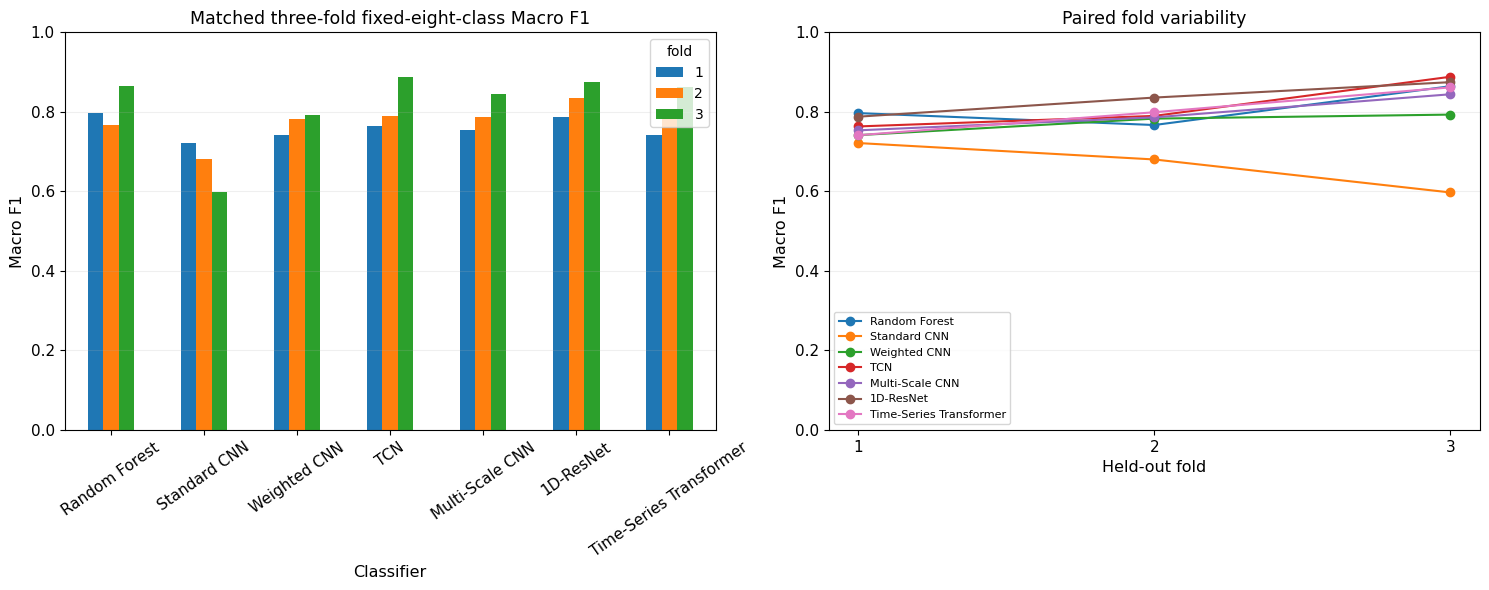

In [8]:
# ================== 07. Compare Matched Fold-Level Macro F1 ==================

# ---------------------- 1. Compare Fold-Level Macro F1 -----------------------
wide=fold_results.pivot(index="model",columns="fold",values="macro_f1"
).reindex(MODEL_NAMES)

display(wide.round(4))
wide.rename_axis("model").reset_index().to_csv(
    output_dir / "22_matched_cv_fold_comparison.csv", index=False
)

# ------------------ 2. Visualise Matched Model Performance -------------------
fig,axes=plt.subplots(1,2,figsize=(15,6))

wide.plot(kind="bar",ax=axes[0],rot=35,ylim=(0,1))
axes[0].set(title="Matched three-fold fixed-eight-class Macro F1",
            xlabel="Classifier",ylabel="Macro F1")

for model in MODEL_NAMES:
    rows=fold_results[fold_results["model"]==model].sort_values("fold")
    axes[1].plot(rows["fold"],rows["macro_f1"],marker="o",label=model)
axes[1].set(title="Paired fold variability",xlabel="Held-out fold",
            ylabel="Macro F1",ylim=(0,1),xticks=[1,2,3])
axes[1].legend(fontsize=8)
for ax in axes: ax.grid(axis="y",alpha=0.2)
fig.tight_layout()
save_figure(fig, output_dir / "22_matched_fold_macro_f1.png")
plt.show()


**08. Inspect Minority Classes and Confusion Matrices**

Report precision, recall, F1 and support for all eight source activities, including Shuffling and both stair classes. Shuffling has only 219 source windows in the bounded cohort. Use consistent class ordering in confusion matrices and interpret pooled window metrics as correlated observations.

,model,class_code,activity,support,precision,recall,f1
0,Random Forest,1,Walking,3591,0.9272,0.9510,0.9390
1,Random Forest,2,Running,1028,0.9836,0.9903,0.9869
2,Random Forest,3,Shuffling,219,0.4756,0.5342,0.5032
3,Random Forest,4,Stairs ascending,192,0.7310,0.5521,0.6291
4,Random Forest,5,Stairs descending,182,0.7031,0.4945,0.5806
5,Random Forest,6,Standing,2227,0.9382,0.9618,0.9499
6,Random Forest,7,Sitting,5599,0.9969,0.9791,0.9879
7,Random Forest,8,Lying,1163,0.9831,0.9991,0.9910
8,Standard CNN,1,Walking,3591,0.8971,0.9563,0.9257
9,Standard CNN,2,Running,1028,0.9873,0.9844,0.9859


,model,activity,support,recall,f1
2,Random Forest,Shuffling,219,0.5342,0.5032
3,Random Forest,Stairs ascending,192,0.5521,0.6291
4,Random Forest,Stairs descending,182,0.4945,0.5806
10,Standard CNN,Shuffling,219,0.0000,0.0000
11,Standard CNN,Stairs ascending,192,0.1198,0.2009
12,Standard CNN,Stairs descending,182,0.2033,0.3318
18,Weighted CNN,Shuffling,219,0.1050,0.1390
19,Weighted CNN,Stairs ascending,192,0.8073,0.5720
20,Weighted CNN,Stairs descending,182,0.6374,0.6170
26,TCN,Shuffling,219,0.3973,0.3392


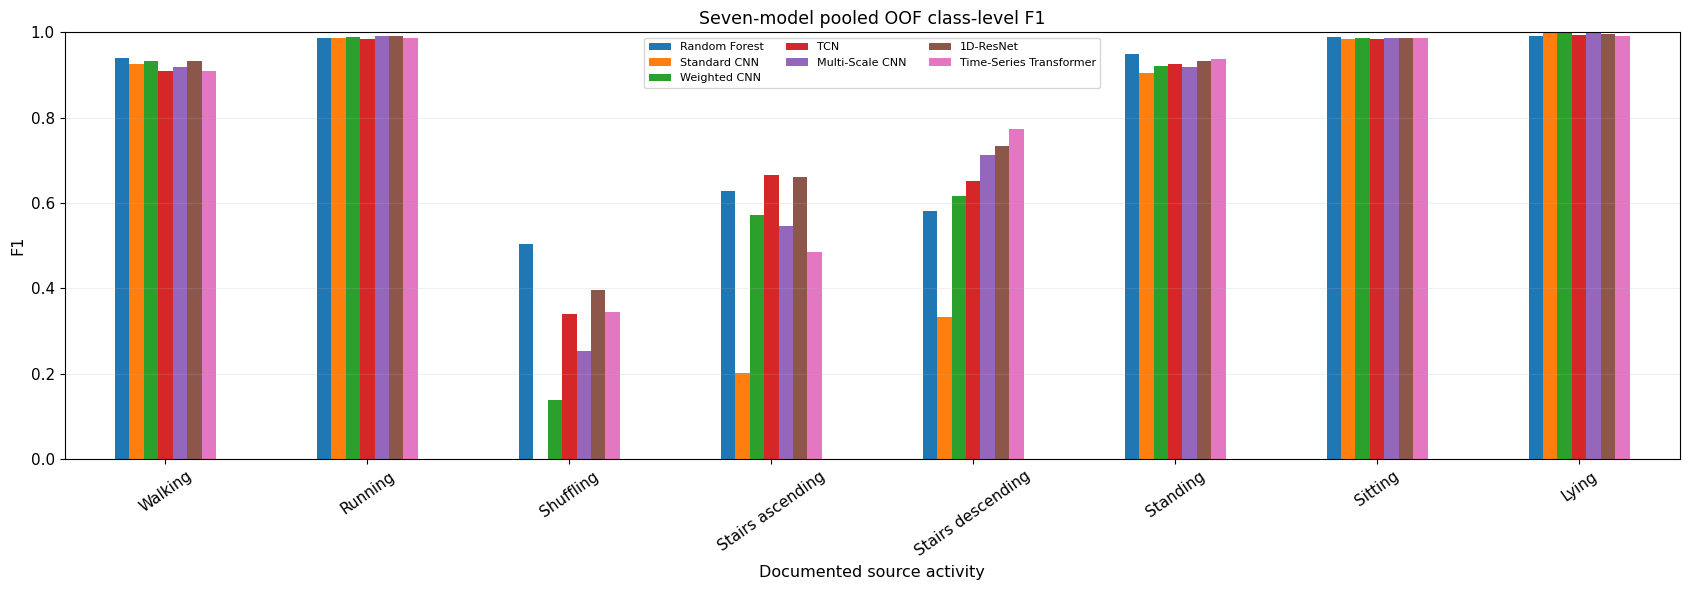

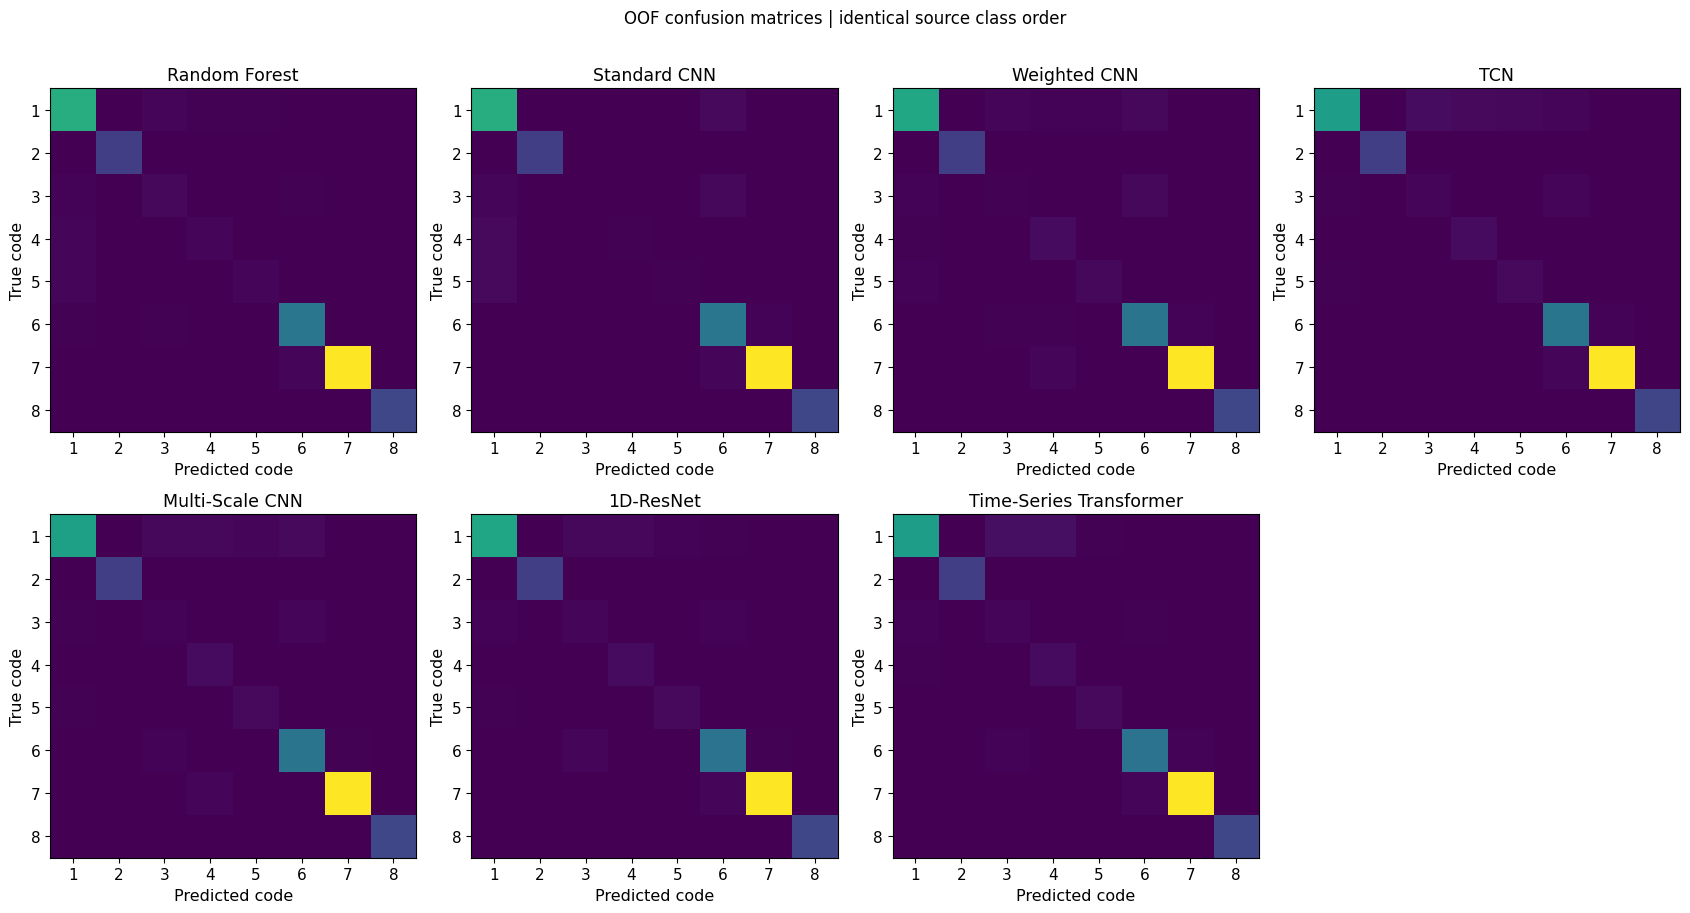

In [9]:
# ============ 08. Inspect Minority Classes and Confusion Matrices ============

# Evidence locator retained for downstream readers: 08. Minority-Class Reporting

# -------------------- 1. Audit Minority-Class Predictions --------------------
class_results["activity"]=class_results["class_code"].map(ACTIVITY_NAMES)
class_results.to_csv(output_dir / "22_matched_cv_class_metrics.csv", index=False)

display(class_results[[
    "model","class_code","activity","support","precision","recall","f1"
]].round(4))
minority=class_results[class_results["class_code"].isin([3,4,5])]
minority.to_csv(output_dir / "22_matched_cv_minority_metrics.csv", index=False)

display(minority[["model","activity","support","recall","f1"]].round(4))

# ------------------- 2. Visualise Class F1 and Confusions --------------------
class_pivot=class_results.pivot(index="activity",columns="model",values="f1")
class_pivot=class_pivot.reindex([ACTIVITY_NAMES[c] for c in CLASSES])
class_pivot=class_pivot.reindex(columns=MODEL_NAMES)
class_pivot.rename_axis("activity").reset_index().to_csv(
    output_dir / "22_matched_cv_per_class_f1.csv", index=False
)

fig,ax=plt.subplots(figsize=(17,6))
class_pivot.plot(kind="bar",ax=ax,rot=35,ylim=(0,1))
ax.set(title="Seven-model pooled OOF class-level F1",
       xlabel="Documented source activity",ylabel="F1")
ax.legend(fontsize=8,ncol=3)
ax.grid(axis="y",alpha=0.2)
fig.tight_layout()
save_figure(fig, output_dir / "22_matched_cv_per_class_f1.png")
plt.show()
fig,axes=plt.subplots(2,4,figsize=(17,9))

for ax,name in zip(axes.flat,MODEL_NAMES):
    matrix=confusion[name]
    ax.imshow(matrix,interpolation="nearest",aspect="auto")
    ax.set(title=name,xlabel="Predicted code",ylabel="True code")
    ax.set_xticks(range(8),CLASSES)
    ax.set_yticks(range(8),CLASSES)
for ax in list(axes.flat)[len(MODEL_NAMES):]:
    ax.axis("off")
fig.suptitle("OOF confusion matrices | identical source class order",y=1.01)
fig.tight_layout()
# ------------------- 3. Export Matched Confusion Matrices --------------------
for name, matrix in confusion.items():
    safe_name = name.lower().replace(" ", "_").replace("-", "_")
    pd.DataFrame(matrix, index=CLASSES, columns=CLASSES).rename_axis(
        "true_class"
    ).to_csv(output_dir / f"22_confusion_{safe_name}.csv")
save_figure(fig, output_dir / "22_matched_cv_confusion_matrices.png")
plt.show()


**09. Examine Participant-Level Model Variation**

Summarise fixed eight-class Macro F1 for each held-out participant rather than treating overlapping windows as independent people. Distinguish fixed-task Macro F1 from metrics restricted to classes observed for one participant. This comparison is not an analysis of demographic fairness.

model,Random Forest,Standard CNN,Weighted CNN,TCN,Multi-Scale CNN,1D-ResNet,Time-Series Transformer
subject_id,,,,,,,
S006,0.6826,0.4580,0.6860,0.7905,0.7214,0.7608,0.7326
S008,0.4254,0.3397,0.3561,0.5138,0.4542,0.5505,0.5578
S009,0.3261,0.2319,0.3460,0.4180,0.4268,0.4100,0.4070
S010,0.4445,0.3540,0.6317,0.5352,0.5428,0.6324,0.5743
S012,0.8718,0.5842,0.7733,0.9325,0.9114,0.9173,0.6181
S013,0.6790,0.5508,0.7424,0.8082,0.8487,0.8677,0.7426
S014,0.8071,0.5887,0.7996,0.7984,0.7315,0.7690,0.8315
S015,0.7156,0.6527,0.7412,0.7410,0.7866,0.8136,0.6370
S016,0.7160,0.6119,0.6119,0.7953,0.7845,0.8592,0.7982


Participants per model: {'Random Forest': 29, 'Standard CNN': 29, 'Weighted CNN': 29, 'TCN': 29, 'Multi-Scale CNN': 29, '1D-ResNet': 29, 'Time-Series Transformer': 29}


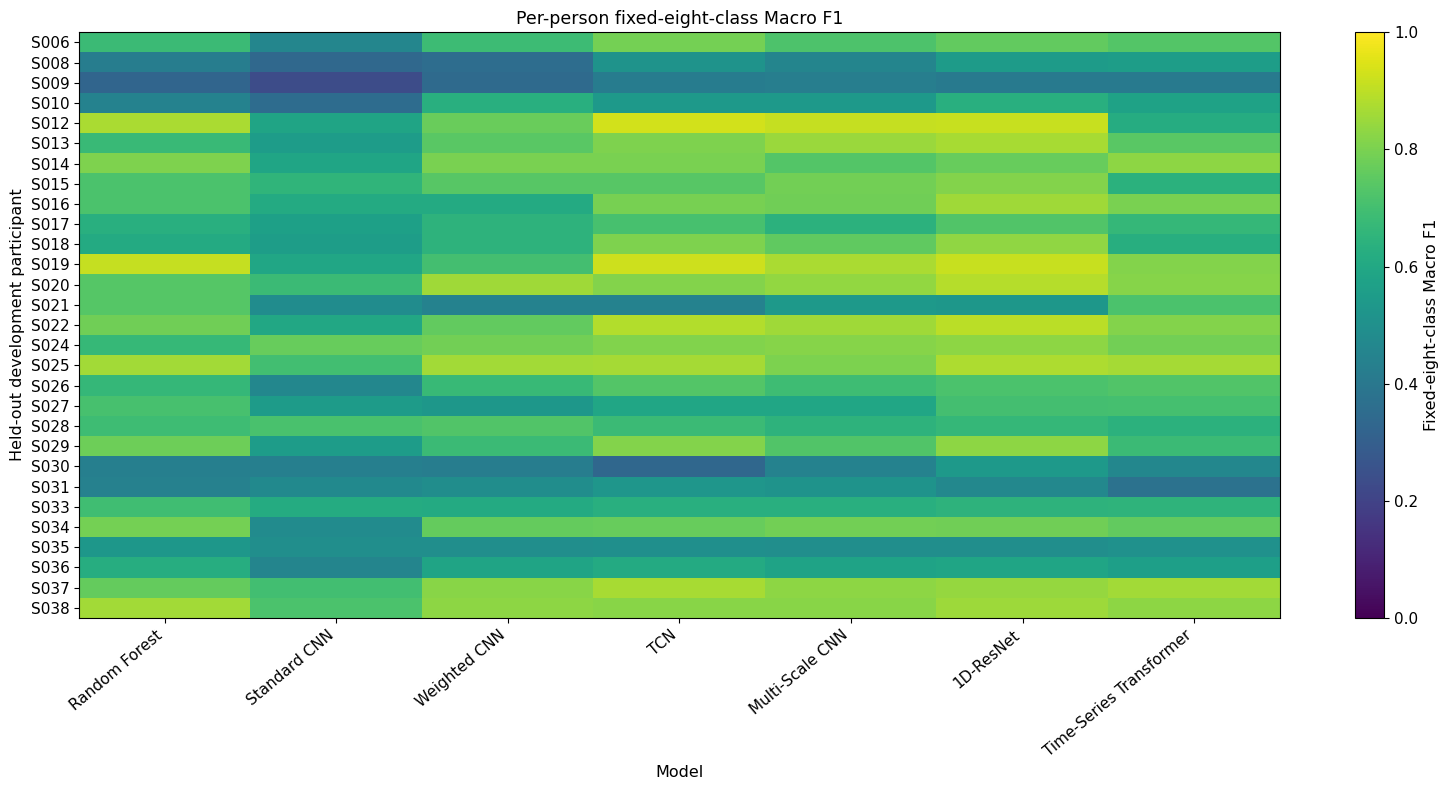

In [10]:
# =============== 09. Examine Participant-Level Model Variation ===============

# ------------------- 1. Summarise Participant-Level Scores -------------------
individual=subject_results.pivot(
    index="subject_id",columns="model",values="macro_f1_fixed_task"
).reindex(index=DEVELOPMENT_SUBJECTS,columns=MODEL_NAMES)

display(individual.round(4))
individual.rename_axis("subject_id").reset_index().to_csv(
    output_dir / "22_matched_cv_participant_comparison.csv", index=False
)
assert individual.notna().all().all()
print("Participants per model:",individual.notna().sum().to_dict())

# ---------------------- 2. Visualise Subject Variation -----------------------
fig,ax=plt.subplots(figsize=(16,8))

im=ax.imshow(individual.to_numpy(),aspect="auto",vmin=0,vmax=1)
ax.set_xticks(range(len(MODEL_NAMES)),MODEL_NAMES,rotation=40,ha="right")
ax.set_yticks(range(len(DEVELOPMENT_SUBJECTS)),DEVELOPMENT_SUBJECTS)
ax.set(title="Per-person fixed-eight-class Macro F1",xlabel="Model",
       ylabel="Held-out development participant")

fig.colorbar(im,ax=ax,label="Fixed-eight-class Macro F1")
fig.tight_layout()
save_figure(fig, output_dir / "22_matched_cv_participant_f1.png")
plt.show()


**10. Report Model Complexity, Runtime and Reproducibility**

Report neural parameter counts, Random Forest tree settings, model-fitting times and Validation inference cost with clear hardware context. Cached job outputs contain predictions and metrics, not reusable trained weights. Final Development fitting and saved inference artefacts were subsequently handled under the separately approved protocol in Notebook 25.

,model,total_train_s,mean_train_s_per_fold,total_validation_inference_s,trainable_parameters
0,1D-ResNet,39.156,13.052,0.174,91176
1,Multi-Scale CNN,9.597,3.199,0.162,16488
2,Random Forest,14.027,4.676,0.170,0
3,Standard CNN,5.872,1.957,0.071,12392
4,TCN,10.995,3.665,0.140,38056
5,Time-Series Transformer,14.942,4.981,0.599,38744
6,Weighted CNN,4.873,1.624,0.054,12392


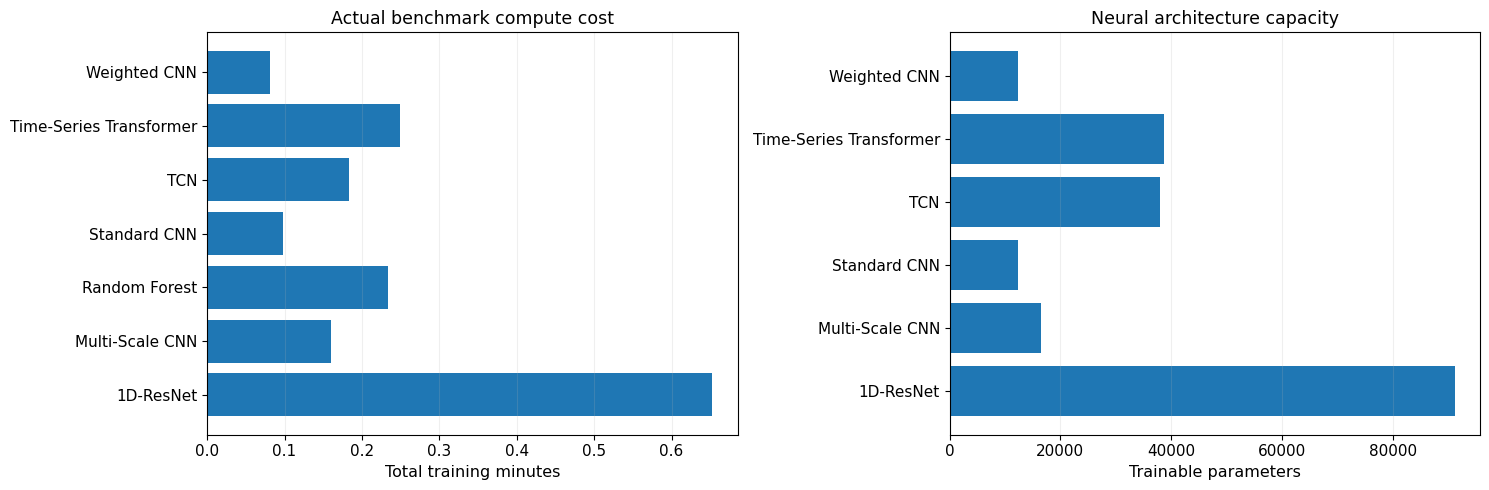

Stored source fingerprint: 672d4109727a20ea30f2557f6b405445fce86be1898a58851fa976f8ed8bf297
Model scores reproduced from actual saved held-out predictions: YES


In [11]:
# ========= 10. Report Model Complexity, Runtime and Reproducibility ==========

# ---------------------- 1. Review Model Training Costs -----------------------
costs=fold_results.groupby("model",as_index=False).agg(
    total_train_s=("train_seconds","sum"),
    mean_train_s_per_fold=("train_seconds","mean"),
    total_validation_inference_s=("validation_inference_seconds","sum"),
    trainable_parameters=("trainable_parameters","max"),
)

display(costs.round(3))
costs.to_csv(output_dir / "22_matched_cv_model_compute_costs.csv", index=False)
fig,axes=plt.subplots(1,2,figsize=(15,5))

axes[0].barh(costs["model"],costs["total_train_s"]/60)
axes[0].set(xlabel="Total training minutes",title="Actual benchmark compute cost")

neural=costs[costs["model"]!="Random Forest"]

axes[1].barh(neural["model"],neural["trainable_parameters"])
axes[1].set(xlabel="Trainable parameters",title="Neural architecture capacity")
for ax in axes: ax.grid(axis="x",alpha=0.2)
fig.tight_layout()
save_figure(fig, output_dir / "22_matched_cv_compute_costs.png")
plt.show()

# ---------------------- 2. Record Benchmark Provenance -----------------------
print("Stored source fingerprint:",plan["fingerprint"])
print("Model scores reproduced from actual saved held-out predictions: YES")


**11. Interpret Development Results and Robustness Context**

These matched Development results support an architecture shortlist, but model choice also requires minority-class performance, participant and fold variability, training cost and seed sensitivity. Notebook 23 subsequently examined selected neural configurations and class-aware losses with repeated seeds. Reserved Test recordings remain outside model selection.

In [12]:
# ========= 11. Interpret Development Results and Robustness Context ==========

# -------------- 1. Interpret Model and Minority-Class Evidence ---------------
shuffling=class_results[class_results["class_code"]==3][["model","f1"]].rename(
    columns={"f1":"shuffling_pooled_f1"}
)

decision=summary.merge(shuffling,on="model",validate="one_to_one")

display(decision.sort_values("macro_f1_mean",ascending=False)[[
    "model","macro_f1_mean","macro_f1_sd",
    "balanced_accuracy_mean","shuffling_pooled_f1",
    "total_train_seconds","parameters"
]].round(4))

# --------------------- 2. State Development Limitations ----------------------
limitations=pd.DataFrame([
    {"issue":"Development-only model comparison","restriction":"No independent Test claim"},
    {"issue":"500-cap label-blind sampling","restriction":"Not full-data optimum or class-balanced task"},
    {"issue":"One seed and three folds","restriction":"Cannot claim strong stability or significance"},
    {"issue":"Different architecture sizes and representations","restriction":"Not isolated causal architecture advantage"},
    {"issue":"Window overlap","restriction":"No independence of window-level observations"},
    {"issue":"Original Test exploratory history","restriction":"S023/S032 not preregistered-unseen"},
])

display(limitations)

# -------------------- 3. Export Interpretation Evidence --------------------
decision.to_csv(output_dir / "22_matched_cv_model_decision_evidence.csv", index=False)
limitations.to_csv(output_dir / "22_matched_cv_limitations.csv", index=False)


,model,macro_f1_mean,macro_f1_sd,balanced_accuracy_mean,shuffling_pooled_f1,total_train_seconds,parameters
0,1D-ResNet,0.8328,0.0435,0.8688,0.3962,39.1565,91176
4,TCN,0.8138,0.0658,0.8575,0.3392,10.9946,38056
2,Random Forest,0.8094,0.0500,0.8063,0.5032,14.0272,0
5,Time-Series Transformer,0.8006,0.0602,0.8552,0.3444,14.9417,38744
1,Multi-Scale CNN,0.7946,0.0459,0.8392,0.2522,9.5974,16488
6,Weighted CNN,0.7725,0.0274,0.8022,0.1390,4.8731,12392
3,Standard CNN,0.6664,0.0633,0.6575,0.0000,5.8722,12392


,issue,restriction
0,Development-only model comparison,No independent Test claim
1,500-cap label-blind sampling,Not full-data optimum or class-balanced task
2,One seed and three folds,Cannot claim strong stability or significance
3,Different architecture sizes and representations,Not isolated causal architecture advantage
4,Window overlap,No independence of window-level observations
5,Original Test exploratory history,S023/S032 not preregistered-unseen


**12. Scientific Completeness and Source-Provenance Gate**

Verify all 21 configured jobs, complete source-row coverage, group separation, finite metrics and reserved Test exclusion. A passing gate establishes consistency of this saved Development evaluation, not independent Test performance or generalisation to new participants and recording settings.

In [13]:
# ========== 12. Scientific Completeness and Source-Provenance Gate ===========

# ------------------- 1. Verify Complete Model-Fold Results -------------------
assert len(jobs)==len(MODEL_NAMES)*FOLDS==21
assert len(fold_results)==21
assert len(predictions)==len(X)*len(MODEL_NAMES)
assert len(subject_results)==len(DEVELOPMENT_SUBJECTS)*len(MODEL_NAMES)
assert len(class_results)==len(MODEL_NAMES)*len(CLASSES)
for name,table in predictions.groupby("model"):
    assert len(table)==len(X) and table["source_row"].is_unique
    assert not(set(table["subject_id"])&RESERVED_TEST)
    np.testing.assert_array_equal(
        table.sort_values("source_row")["true_label"].to_numpy(),y
    )

assert fold_results["macro_f1"].between(0,1).all()
assert class_results["f1"].between(0,1).all()

# ------------------- 2. Check Class Metrics and Provenance -------------------
assert all(confusion[name].shape==(8,8) for name in MODEL_NAMES)

print(""+"="*70)
print("STAGE 22 | SEVEN-MODEL MATCHED GROUPED DEVELOPMENT BENCHMARK")
print("="*70)
print("Seven model families evaluated:",len(MODEL_NAMES))
print("Complete model/fold jobs:",len(jobs))
print("Independent Development participants:",len(DEVELOPMENT_SUBJECTS))
print("Validation source rows per model:",len(X))
print("Fixed eight-class metrics: PASSED")
print("Matched source-row and subject-fold identities: PASSED")
print("All seven actual training/evaluation runs: PASSED")
print("Original protected Test participants accessed: NO")
print("-"*70)

# ------------------------ 3. Scientific Quality Gate -------------------------
print("Stage 22 scientific quality gate: PASSED")
print("Independent full-dataset generalisation established: NO")
print("Final model selection performed: NO")
print("Next stage: Stage 23 - Multi-Seed and Class-Imbalance Robustness")

download_outputs_from_colab(folder="wearable_activity_recognition/output", stage="22")

STAGE 23 | SEVEN-MODEL MATCHED GROUPED DEVELOPMENT BENCHMARK
Seven model families evaluated: 7
Complete model/fold jobs: 21
Independent Development participants: 29
Validation source rows per model: 14201
Fixed eight-class metrics: PASSED
Matched source-row and subject-fold identities: PASSED
All seven actual training/evaluation runs: PASSED
Original protected Test participants accessed: NO
----------------------------------------------------------------------
Stage 23 scientific quality gate: PASSED
Independent full-dataset generalisation established: NO
Final model selection performed: NO
Next stage: Stage 24 - Multi-Seed and Class-Imbalance Robustness
